# Nonsmooth functions


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from utilities.function_library import abs_corner, step_ridge
from utilities.orponet import OrPoNet
from utilities.training import Trainer


## 1. Settings


In [2]:
SEED = 42
DEVICE = torch.device("cpu")
DTYPE = torch.float64
torch.set_num_threads(1)


In [3]:
def sample_points(count, seed):
    generator = torch.Generator().manual_seed(seed)
    return (2 * torch.rand(count, 2, generator=generator, dtype=DTYPE) - 1).to(DEVICE)


def make_model(degree):
    model = OrPoNet(
        basis_configs=[
            {"type": "chebyshev", "degree": degree, "constant_channels": 2}
            for _ in range(2)
        ],
        data_domain_lb=[-1, -1],
        data_domain_ub=[1, 1],
        training_domain_lb=[-1, -1],
        training_domain_ub=[1, 1],
        coeff_init_std=0.1,
        neuron_copies=1,
        normalize_basis=False,
        dtype=DTYPE,
    ).to(DEVICE)
    # Preserve the source's Gaussian fan-in initialization (gain 0.05), without
    # bringing back the removed auto-mode API. This example uses no basis-aware reset.
    for layer in model._hidden_layers[1:]:
        weight = layer.projection_w
        torch.nn.init.normal_(weight, std=0.05 / np.sqrt(weight.shape[0]))
    weight = model._output_weight
    torch.nn.init.normal_(weight, std=0.05 / np.sqrt(weight.shape[1] * weight.shape[2]))
    return model


## 2. Train each order


In [4]:
LBFGS_STEPS = 25


def train_model(model, train_x, train_y, test_x, test_y):
    trainer = Trainer(model, (train_x, train_y), (test_x, test_y), selection=None)
    loader = DataLoader(
        TensorDataset(train_x, trainer.train_targets),
        batch_size=len(train_x),
        shuffle=False,
    )
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.002, weight_decay=1e-8)
    trainer.fit(optimizer, epochs=800, batches=loader)
    if LBFGS_STEPS > 0:
        optimizer = torch.optim.LBFGS(
            model.parameters(),
            lr=0.8,
            max_iter=40,
            history_size=100,
            tolerance_grad=1e-12,
            tolerance_change=1e-12,
            line_search_fn="strong_wolfe",
        )
        trainer.fit_lbfgs(optimizer, steps=LBFGS_STEPS)
    # Final-state error, not the minimum over training.
    mse = trainer.history.iloc[-1]["validation_mse"]
    if not np.isfinite(mse):
        raise FloatingPointError("Non-finite test MSE in the nonsmooth sweep.")
    return mse


In [5]:
DEGREES = [4, 8, 16, 32]
SLICE_DEGREES = [4, 16]
TRAIN_SAMPLES = 2048
TEST_SAMPLES = 4096
problems = [("abs_corner", abs_corner), ("step_ridge", step_ridge)]

test_x = sample_points(TEST_SAMPLES, SEED + 10000)
x = torch.linspace(-1, 1, 1201, dtype=DTYPE, device=DEVICE)
slice_points = torch.stack([x, torch.zeros_like(x)], dim=1)
results = {}

for example_index, (name, target) in enumerate(problems):
    train_x = sample_points(TRAIN_SAMPLES, SEED + 100 * example_index)
    train_y, test_y = target(train_x), target(test_x)
    errors, slices = [], {}
    for degree in DEGREES:
        torch.manual_seed(SEED + 1000 * example_index + degree)
        model = make_model(degree)
        error = train_model(model, train_x, train_y, test_x, test_y)
        errors.append(error)
        if degree in SLICE_DEGREES:
            with torch.no_grad():
                slices[degree] = model(slice_points).squeeze(1).cpu().numpy()
        print(f"{name}, order {degree}: test MSE = {error:.3e}", flush=True)
    results[name] = {
        "mse": np.array(errors),
        "slices": slices,
        "target": target(slice_points).squeeze(1).cpu().numpy(),
    }
x = x.cpu().numpy()


abs_corner, order 4: test MSE = 2.759e-03


abs_corner, order 8: test MSE = 5.398e-04


abs_corner, order 16: test MSE = 1.598e-04


abs_corner, order 32: test MSE = 7.066e-04


step_ridge, order 4: test MSE = 1.424e-01


step_ridge, order 8: test MSE = 7.823e-02


step_ridge, order 16: test MSE = 5.109e-02


step_ridge, order 32: test MSE = 1.232e-01


## 3. Slices and test error


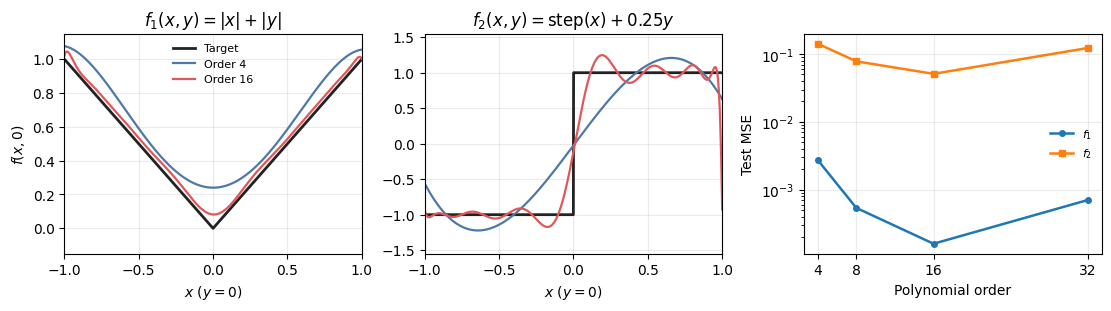

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), constrained_layout=True)

axes[0].plot(
    x, results["abs_corner"]["target"], color="#222222", linewidth=2, label="Target"
)
axes[0].plot(
    x,
    results["abs_corner"]["slices"][4],
    color="#4E79A7",
    linewidth=1.6,
    label="Order 4",
)
axes[0].plot(
    x,
    results["abs_corner"]["slices"][16],
    color="#E15759",
    linewidth=1.6,
    label="Order 16",
)
axes[0].set(
    title=r"$f_1(x,y)=|x|+|y|$",
    xlabel=r"$x$ ($y=0$)",
    ylabel=r"$f(x,0)$",
    xlim=(-1, 1),
    ylim=(-0.15, 1.15),
)
axes[0].set_xticks([-1, -0.5, 0, 0.5, 1])
axes[0].grid(True, alpha=0.25)
axes[0].legend(frameon=False, fontsize=8, loc="upper center")

axes[1].plot(x, results["step_ridge"]["target"], color="#222222", linewidth=2)
axes[1].plot(x, results["step_ridge"]["slices"][4], color="#4E79A7", linewidth=1.6)
axes[1].plot(x, results["step_ridge"]["slices"][16], color="#E15759", linewidth=1.6)
axes[1].set(
    title=r"$f_2(x,y)=\mathrm{step}(x)+0.25y$",
    xlabel=r"$x$ ($y=0$)",
    xlim=(-1, 1),
    ylim=(-1.55, 1.55),
)
axes[1].set_xticks([-1, -0.5, 0, 0.5, 1])
axes[1].grid(True, alpha=0.25)

axes[2].semilogy(
    DEGREES,
    results["abs_corner"]["mse"],
    "o-",
    linewidth=1.8,
    markersize=4,
    label=r"$f_1$",
)
axes[2].semilogy(
    DEGREES,
    results["step_ridge"]["mse"],
    "s-",
    linewidth=1.8,
    markersize=4,
    label=r"$f_2$",
)
axes[2].set(xlabel="Polynomial order", ylabel="Test MSE")
axes[2].set_xticks(DEGREES)
axes[2].grid(True, alpha=0.25)
axes[2].legend(frameon=False, fontsize=8)
plt.show()
